## Exercise 4: SGD with Dataset and DataLoader


In this notebook, we will see how stochastic gradient descent can be implemented with PyTorch.
We will again use the polynomial regression example from the homework of week 2.

In [1]:
import matplotlib as mpl
import matplotlib.pyplot as plt
import torch

This cell defines synthetic data that the model will have to fit. The ground-truth targets follow a degree-3 polynomial plus Gaussian noise.

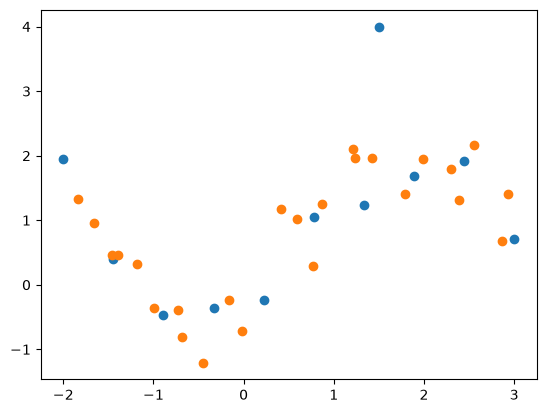

In [2]:
torch.manual_seed(123)
torch.use_deterministic_algorithms(True)
if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = False

n_points = 10


def make_targets(x):
    return x + 0.5 * x**2 - 0.25 * x**3 + 0.4 * torch.randn_like(x)


x = torch.linspace(-2, 3, n_points).reshape(-1, 1)
y = make_targets(x)

x = torch.concat((x, torch.tensor((1.5,)).reshape(-1, 1)), dim=0)
y = torch.concat((y, torch.tensor((4,)).reshape(-1, 1)), dim=0)

x_val = torch.linspace(-2, 3, 25).reshape(-1, 1) + 0.1 * torch.randn((25, 1))
y_val = make_targets(x_val)

plt.scatter(x, y)
plt.scatter(x_val, y_val)

### Step 1: Dataset class

Let us collect these data points in a `torch.utils.data.Dataset`.
This will allow us later to easily sample batches of data using `torch.utils.data.DataLoader`.

In [3]:
class MyDataset(torch.utils.data.Dataset):
    def __init__(self, x, y):
        self.x = x
        self.y = y

    def __getitem__(self, idx):
        return self.x[idx], self.y[idx]

    def __len__(self):
        return self.x.size(0)


# Alternatively use torch.utils.data.TensorDataset
# PyTorch also provides ready-made datasets (e.g., in torchvision)

# Test that the dataset can be indexed
dataset = MyDataset(x, y)
print(dataset[0])
print(len(dataset))

(tensor([-2.]), tensor([1.9554]))
11


The model is defined as before.

In [4]:
class PolyRegression(torch.nn.Module):
    def __init__(self, poly_degree: int):
        super().__init__()

        self.max_degree = poly_degree
        self.linear = torch.nn.Linear(self.max_degree, 1, bias=True)

    def forward(self, x):
        exponentiated_features = torch.concat(
            [torch.pow(x, exponent) for exponent in range(1, self.max_degree + 1)],
            dim=1,
        )
        return self.linear(exponentiated_features)


# Test that the model works
model = PolyRegression(3)
out = model(x)

The general training steps remain the same.

In [5]:
# Renamed from train_one_epoch to train_one_step, because the arguments x, y do not
# necessarily include all data points of the dataset.
def train_one_step(x, y, model, optimizer, loss_func):
    output = model(x)  # Step 1: forward pass
    loss = loss_func(output, y)  # Step 2: Compute loss
    optimizer.zero_grad()  # Step 3: Zero all .grad attributes
    loss.backward()  # Step 4: Compute gradients (populate .grad attributes)
    optimizer.step()  # Step 5: Update parameters based on gradients
    return loss.item()

Evaluation remains the same as well.

In [6]:
@torch.inference_mode()
def eval(x, y, model, loss_func):
    output = model(x)
    loss = loss_func(output, y)
    return loss.item()

Here we add a function that plots the loss as a function of a single parameter while all other parameters stay fixed (a 1-D slice of the loss landscape).
We will come back to this once we have seen how the training loop is modified for batch-wise training.

In [7]:
@torch.inference_mode()
def visualize_loss_landscape(
    x, y, model, loss_func, i, total_steps, param_idx=-1, label=None
):
    model_copy = PolyRegression(model.max_degree)
    model_copy.load_state_dict(model.state_dict())

    cmap = mpl.colormaps["viridis"]
    orig_param_val = model_copy.linear.weight.data[0, param_idx].item()
    param_grid = torch.linspace(-5, 5, 30)
    losses = []
    for param_val in param_grid:
        model_copy.linear.weight.data[0, param_idx] = param_val
        losses.append(loss_func(model_copy(x), y).item())

    label = label if label else i
    plt.plot(param_grid, losses, color=cmap(i / total_steps), label=label)
    plt.scatter(
        orig_param_val, loss_func(model(x), y).item(), color=cmap(i / total_steps)
    )

Here, we combine everything into the main training loop. DataLoader!

epoch=0: train_loss=14.769138032739813 val_loss=11.813751220703125
epoch=5: train_loss=9.108717745000666 val_loss=7.095385551452637
epoch=10: train_loss=5.297451105984774 val_loss=3.881148099899292
epoch=15: train_loss=3.105454748327082 val_loss=2.076066017150879
epoch=20: train_loss=1.9247723059220747 val_loss=1.2078076601028442
epoch=25: train_loss=1.467079292644154 val_loss=0.8374459743499756
epoch=30: train_loss=1.308830120346763 val_loss=0.710532546043396
epoch=35: train_loss=1.2532053820111535 val_loss=0.6742842197418213
epoch=40: train_loss=1.2319888093254783 val_loss=0.6589319109916687
epoch=45: train_loss=1.217375787821683 val_loss=0.6483423113822937
epoch=50: train_loss=1.2003736766901882 val_loss=0.6381242275238037
epoch=55: train_loss=1.1869974922050128 val_loss=0.6280276775360107
epoch=60: train_loss=1.1682272174141624 val_loss=0.617857038974762
epoch=65: train_loss=1.152152424508875 val_loss=0.6070212721824646
epoch=70: train_loss=1.132825797254389 val_loss=0.596393764019

Text(0.5, 0, 'Parameter')

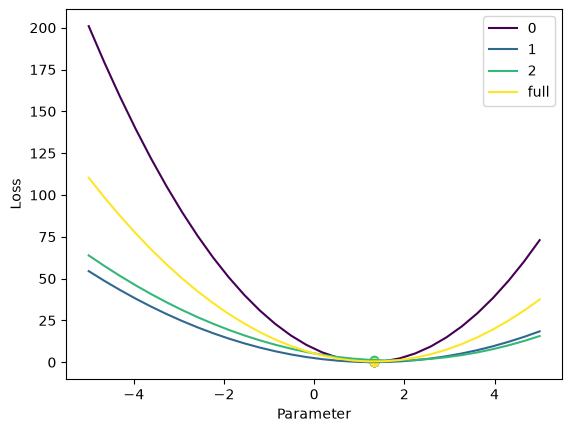

In [8]:
degree = 3
torch.manual_seed(123)  # fixes initialization of parameters

model_mse = PolyRegression(degree)
# Larger batch size ussually means we need a larger learning rate
optimizer = torch.optim.Adam(model_mse.parameters(), lr=5e-3)
loss_func = torch.nn.MSELoss()

# To get batches we add a DataLoader
# shuffle=True reshuffles the data at the start of every epoch
dataset = MyDataset(x, y)
loader = torch.utils.data.DataLoader(dataset, batch_size=4, shuffle=True)

# reduce number of epochs from 5k, because we now have 5k * (num_samples/batch_size = n/b) training steps.
# Each epoch now performs ⌈n/b⌉ ~= 3 updates instead of 1, so we need fewer epochs
n_epochs = 1000
print_every_n_epochs = 5
for epoch in range(n_epochs):
    # We now get one loss per batch instead of one for the whole dataset, so we aggregate the batch losses over the epoch.
    # (you could also print a running mean over the last x batches)
    train_loss = 0

    # We iterate over the data loader to get batches
    for step, (x_batch, y_batch) in enumerate(loader):
        train_loss += train_one_step(
            x_batch, y_batch, model_mse, optimizer, loss_func
        ) * len(x_batch)
    train_loss /= len(dataset)
    if epoch % print_every_n_epochs == 0:
        val_loss = eval(x_val, y_val, model_mse, loss_func)
        print(f"{epoch=}: train_loss={train_loss} val_loss={val_loss}")

# How does the loss landscape (and thus the gradients) change for different batches?
param_idx = 0
for step, (x_batch, y_batch) in enumerate(loader):
    visualize_loss_landscape(
        x_batch, y_batch, model_mse, loss_func, step, len(loader), param_idx
    )
visualize_loss_landscape(x, y, model_mse, loss_func, 11, 11, param_idx, label="full")
plt.legend()
plt.ylabel("Loss")
plt.xlabel("Parameter")

As before, we can visualize the final model; it should have found a similar curve.

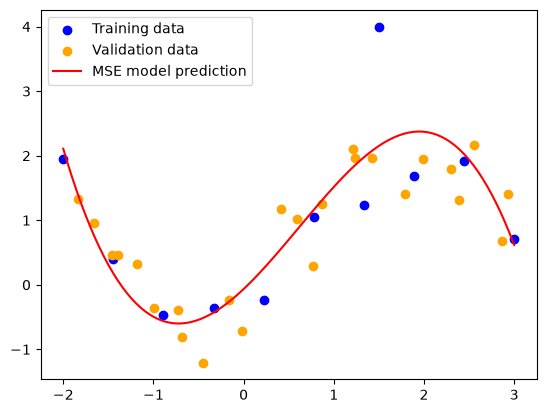

In [9]:
fig, ax = plt.subplots()
ax.scatter(x.view(-1), y.view(-1), color="blue", label="Training data")
ax.scatter(x_val.view(-1), y_val.view(-1), color="orange", label="Validation data")

with torch.no_grad():
    x_plot = torch.linspace(x.min().item(), x.max().item(), 100).view(-1, 1)
    pred_plot = model_mse(x_plot)
    ax.plot(x_plot, pred_plot, label="MSE model prediction", color="red")

ax.legend()